## principales caracteristicas
El dataset esta compuesto por audios de 1 segundo de una persona hablando una palabra en ingles, cada etiqueta de la palabra se encuentra en el nombre de la carpeta, no hay datos del hablante (ni edad, ni genero, etc.). Cada carpeta esta compuesta por vairas tomas de cada hablante esta identificado por un hash delante y luego un índice final de cada toma.

In [25]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
import torch
import torchaudio



In [26]:
data_dir= r"data"

In [27]:
# exploramos
datos = []
for root, dirs, files in os.walk(data_dir):
    for file in files:
        # os.path.join construye la ruta completa de forma segura para cualquier sistema operativo
        ruta_completa = os.path.join(root, file)
        print(ruta_completa)

data/train/LICENSE
data/train/.DS_Store
data/train/dataset_con_metricas.csv
data/train/testing_list.txt
data/train/validation_list.txt
data/train/README.md
data/train/one/b97c9f77_nohash_2.wav
data/train/one/c948d727_nohash_3.wav
data/train/one/05cf43ef_nohash_0.wav
data/train/one/5b09db89_nohash_1.wav
data/train/one/8134f43f_nohash_1.wav
data/train/one/a1e71565_nohash_0.wav
data/train/one/f8ad3941_nohash_0.wav
data/train/one/81a345a3_nohash_0.wav
data/train/one/f19d1738_nohash_1.wav
data/train/one/7d86b703_nohash_1.wav
data/train/one/61e2f74f_nohash_0.wav
data/train/one/14775481_nohash_0.wav
data/train/one/0a196374_nohash_0.wav
data/train/one/131e738d_nohash_3.wav
data/train/one/f104f742_nohash_0.wav
data/train/one/0d6d7360_nohash_3.wav
data/train/one/ace072ba_nohash_3.wav
data/train/one/b843de62_nohash_0.wav
data/train/one/ce0cb033_nohash_0.wav
data/train/one/76b58705_nohash_1.wav
data/train/one/e9901cf0_nohash_0.wav
data/train/one/61ab8fbc_nohash_3.wav
data/train/one/8134f43f_nohash

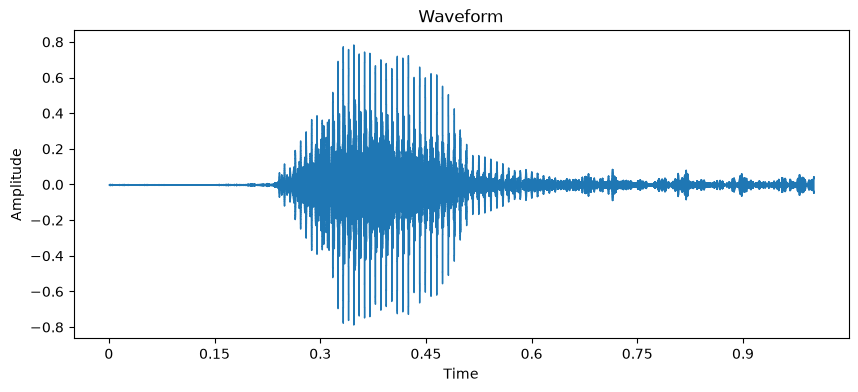

Mean: 1.7812339137890376e-05, Median: 0.00040914781857281923, Variance: 0.008622154593467712


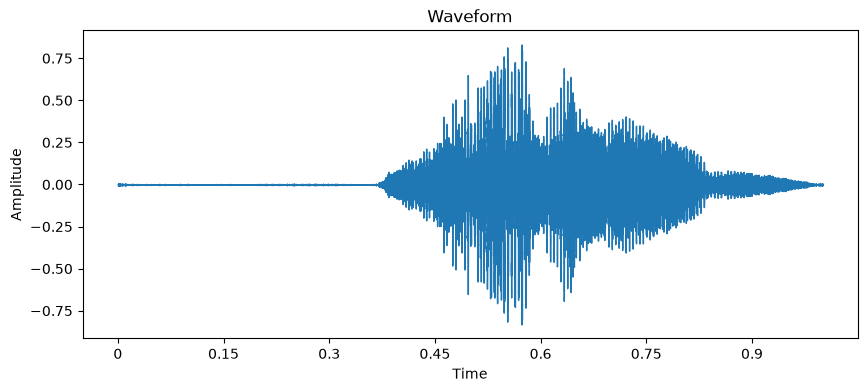

Mean: 6.048574869055301e-05, Median: 5.828906432725489e-05, Variance: 0.014457154087722301


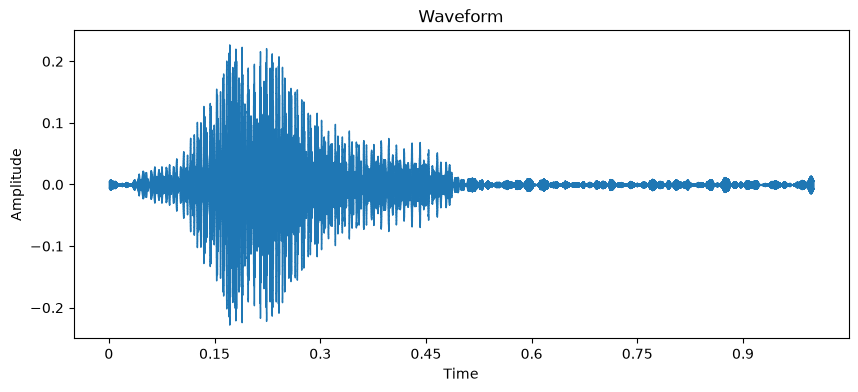

Mean: -8.249750680988654e-05, Median: 0.0007470747223123908, Variance: 0.0014567469479516149


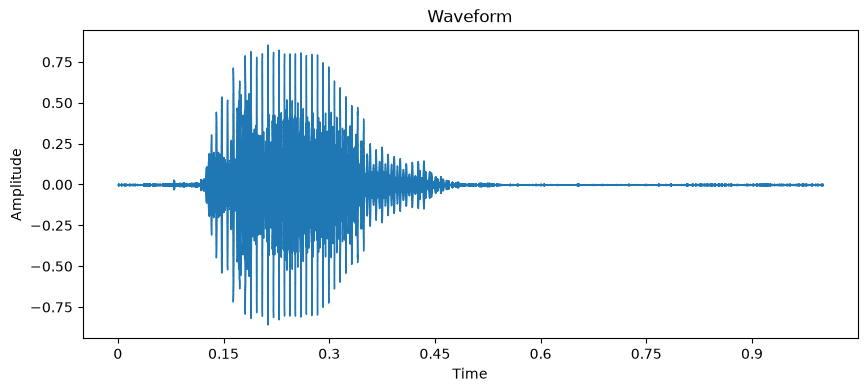

Mean: 1.0973471944453195e-05, Median: -0.0004533413448370993, Variance: 0.01739867404103279


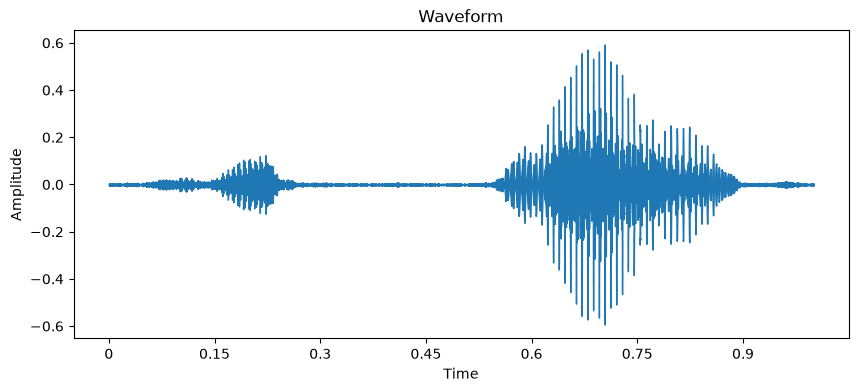

Mean: 8.492547931382433e-05, Median: 0.0005053004715591669, Variance: 0.004348552320152521


In [28]:
listado_muestra= ["data/train/one/b97c9f77_nohash_2.wav",
"data/train/one/c948d727_nohash_3.wav",
"data/train/one/05cf43ef_nohash_0.wav",
"data/train/one/5b09db89_nohash_1.wav",
"data/train/one/8134f43f_nohash_1.wav"]

for muestra in listado_muestra:
    y, sr = librosa.load(muestra)
    plt.figure(figsize=(10, 4))
    librosa.display.waveshow(y, sr=sr)
    plt.title('Waveform')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.show()
    mean = np.mean(y)
    median = np.median(y)
    variance = np.var(y)
    print(f"Mean: {mean}, Median: {median}, Variance: {variance}")

## Preparación
Como son palabras vamos a utilizar algunas herramientas que se relacionan con los fonemas para ver que tal nos va, la idea es armar un dataset con los calculos obtenidos.
Utilizaremos las primeras tres formantes.

F1:  Indica la altura o abertura de la lengua. Es bajo en vocales cerradas como [i, u] y alto en vocales abiertas como [a].

F2:  Indica la posición anterior o posterior de la lengua. Ayuda a distinguir entre vocales palatales (frente) y velares (fondo).

F3:  Aporta matices sobre la forma de los labios y la naturalidad del sonido.

Tambien es muy utilizado:

MFCC: Coeficientes Cepstrales en las Frecuencias Mel, son parámetros que representan la envolvente espectral de una señal de audio y se usan de forma masiva en el reconocimiento de voz y procesamiento de sonido.

In [29]:
data_dir = "data/train"
datos = []

for root, dirs, files in os.walk(data_dir):
  for file in files:
    # 1. Excluir todo lo que no sea .wav
    if not file.endswith(".wav"):
      continue

    ruta_completa = os.path.join(root, file)

    # 2. Obtener la palabra (nombre de la carpeta contenedora)
    word = os.path.basename(root)

    # 3. Parsear el nombre del archivo (ej: f19d1738_nohash_1.wav)
    nombre_base = file[:-4]  # Remueve '.wav'
    if "_nohash_" in nombre_base:
      person, take = nombre_base.split("_nohash_")
    else:
      # Plan de respaldo por si algún archivo tiene otro formato
      partes = nombre_base.split("_")
      person = partes[0]
      take = partes[-1]

    # Guardar los datos en una lista de diccionarios
    datos.append(
        {"person": person, "take": take, "word": word, "path": ruta_completa}
    )

# 4. Crear el DataFrame
df = pd.DataFrame(datos)

# Agregar la columna 'id' autoincremental al inicio
df.insert(0, "id", range(len(df)))

# Ver los primeros resultados
print(df.head())

   id    person take word                                  path
0   0  b97c9f77    2  one  data/train/one/b97c9f77_nohash_2.wav
1   1  c948d727    3  one  data/train/one/c948d727_nohash_3.wav
2   2  05cf43ef    0  one  data/train/one/05cf43ef_nohash_0.wav
3   3  5b09db89    1  one  data/train/one/5b09db89_nohash_1.wav
4   4  8134f43f    1  one  data/train/one/8134f43f_nohash_1.wav


In [30]:
len(df)

105835

In [31]:
data_dir = "data/test"
datos_test = []

for root, dirs, files in os.walk(data_dir):
  for file in files:
    # 1. Excluir todo lo que no sea .wav
    if not file.endswith(".wav"):
      continue

    ruta_completa = os.path.join(root, file)

    # 2. Obtener la palabra (nombre de la carpeta contenedora)
    word = os.path.basename(root)

    # 3. Parsear el nombre del archivo (ej: f19d1738_nohash_1.wav)
    nombre_base = file[:-4]  # Remueve '.wav'
    if "_nohash_" in nombre_base:
      person, take = nombre_base.split("_nohash_")
    else:
      # Plan de respaldo por si algún archivo tiene otro formato
      partes = nombre_base.split("_")
      person = partes[0]
      take = partes[-1]

    # Guardar los datos en una lista de diccionarios
    datos_test.append(
        {"person": person, "take": take, "word": word, "path": ruta_completa}
    )

# 4. Crear el DataFrame
df_test = pd.DataFrame(datos_test)

# Agregar la columna 'id' autoincremental al inicio
df_test.insert(0, "id", range(len(df_test)))

# Ver los primeros resultados
print(df_test.head())

   id            person   take       word  \
0   0      wow_af405b69  0.wav  _unknown_   
1   1     zero_bb05582b  0.wav  _unknown_   
2   2  forward_4c6167ca  5.wav  _unknown_   
3   3  forward_f9643d42  2.wav  _unknown_   
4   4    three_91b03183  3.wav  _unknown_   

                                                path  
0  data/test/_unknown_/wow_af405b69_nohash_0.wav.wav  
1  data/test/_unknown_/zero_bb05582b_nohash_0.wav...  
2  data/test/_unknown_/forward_4c6167ca_nohash_5....  
3  data/test/_unknown_/forward_f9643d42_nohash_2....  
4  data/test/_unknown_/three_91b03183_nohash_3.wa...  


In [32]:
len(df_test) # 5%

4890

In [ ]:
# con CPU
# Listas temporales para almacenar los nuevos valores
f1_list = []
f2_list = []
f3_list = []
mfcc_lists = []

# Iterar sobre las rutas de los audios que ya están en el DataFrame
for ruta_completa in df["path"]:
  try:
    # 1. Cargar el audio
    y, sr = librosa.load(ruta_completa, sr=None)

    # 2. Calcular MFCCs (media a lo largo del tiempo)
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    mfccs_mean = np.mean(mfccs, axis=1)  # Vector de 13 valores
    mfcc_lists.append(mfccs_mean)

    # 3. Estimar Formantes (F1, F2, F3) usando LPC
    y_preemph = librosa.effects.preemphasis(y)
    lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))

    roots = np.roots(lpc_coeffs)
    roots = roots[np.imag(roots) > 0]
    ang = np.angle(roots)
    frequencies = sorted(ang * (sr / (2 * np.pi)))

    f1 = frequencies[0] if len(frequencies) > 0 else np.nan
    f2 = frequencies[1] if len(frequencies) > 1 else np.nan
    f3 = frequencies[2] if len(frequencies) > 2 else np.nan

    f1_list.append(f1)
    f2_list.append(f2)
    f3_list.append(f3)

  except Exception as e:
    print(f"Error procesando {ruta_completa}: {e}")
    f1_list.append(np.nan)
    f2_list.append(np.nan)
    f3_list.append(np.nan)
    mfcc_lists.append([np.nan] * 13)

# 4. Agregar las columnas de Formantes al DataFrame
df["F1"] = f1_list
df["F2"] = f2_list
df["F3"] = f3_list

# 5. Convertir la lista de MFCCs en un DataFrame auxiliar y unirlos al original
mfcc_df = pd.DataFrame(
    mfcc_lists, columns=[f"MFCC_{i}" for i in range(1, 14)]
)
df = pd.concat([df.reset_index(drop=True), mfcc_df], axis=1)

# Ver las primeras filas con las nuevas columnas incorporadas
print(df[["id", "person", "word", "F1", "F2", "F3", "MFCC_1"]].head())

KeyboardInterrupt: 

In [33]:
# con GPU

# 1. Configurar el dispositivo (CUDA)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Calculando MFCCs en: {device}")

# 2. Definir la transformación de MFCC en PyTorch y enviarla a la GPU
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=16000,
    n_mfcc=13,
    melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23},
).to(device)

mfcc_lists = []
f1_list, f2_list, f3_list = [], [], []

for ruta_completa in df["path"]:
  try:
    # A. Cargar el audio con Librosa (Evita por completo el error de TorchCodec)
    y, sr = librosa.load(ruta_completa, sr=16000)

    # Convertir el array a Tensor de PyTorch y enviarlo a la GPU (CUDA)
    waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)

    # B. Calcular MFCCs directamente en la GPU
    mfccs = mfcc_transform(waveform)  # Forma: [1, n_mfcc, tiempo]
    mfccs_mean = (
        mfccs.mean(dim=-1).squeeze(0).cpu().numpy()
    )  # Promedio y vuelta a CPU
    mfcc_lists.append(mfccs_mean)

    # C. Cálculo de Formantes (F1, F2, F3) usando LPC en CPU
    y_preemph = librosa.effects.preemphasis(y)
    lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))

    roots = np.roots(lpc_coeffs)
    roots = roots[np.imag(roots) > 0]
    ang = np.angle(roots)
    frequencies = sorted(ang * (sr / (2 * np.pi)))

    f1_list.append(frequencies[0] if len(frequencies) > 0 else np.nan)
    f2_list.append(frequencies[1] if len(frequencies) > 1 else np.nan)
    f3_list.append(frequencies[2] if len(frequencies) > 2 else np.nan)

  except Exception as e:
    print(f"Error procesando {ruta_completa}: {e}")
    mfcc_lists.append([np.nan] * 13)
    f1_list.append(np.nan)
    f2_list.append(np.nan)
    f3_list.append(np.nan)

# 3. Integrar los resultados al DataFrame original
df["F1"] = f1_list
df["F2"] = f2_list
df["F3"] = f3_list

mfcc_df = pd.DataFrame(
    mfcc_lists, columns=[f"MFCC_{i}" for i in range(1, 14)]
)
df = pd.concat([df.reset_index(drop=True), mfcc_df], axis=1)

print(df[["id", "person", "word", "F1", "MFCC_1"]].head())

Calculando MFCCs en: cuda
   id    person word          F1      MFCC_1
0   0  b97c9f77  one  876.743225 -108.427750
1   1  c948d727  one  964.770569  -91.981880
2   2  05cf43ef  one  596.072571 -156.440674
3   3  5b09db89  one  646.626892 -116.872467
4   4  8134f43f  one  578.075989 -107.512894


In [34]:
# guardo el dataset calculado para evitar volver a calcular
ruta_archivo_calculado = f"data/train/dataset_con_metricas.csv"
df.to_csv(ruta_archivo_calculado, index=False)

In [38]:
# 1. Contar cuántos NaN hay en total en todo el DataFrame
total_nans = df.isna().sum().sum()
print(f"Total de valores NaN en el DataFrame: {total_nans}")

# 2. Ver cuántos NaN hay por cada columna (muestra solo las que tienen alguno)
nans_por_columna = df.isna().sum()
print("\nConteo de NaN por columna:")
print(nans_por_columna[nans_por_columna > 0])

# 3. Filtrar y ver cuáles filas (audios) tienen valores NaN
filas_con_nans = df[df.isna().any(axis=1)]

Total de valores NaN en el DataFrame: 2

Conteo de NaN por columna:
F3    2
dtype: int64


In [39]:
df_limpio = df.dropna().reset_index(drop=True)

## Baseline

Ya con este dataset formado y caracteristicas calculadas probamos regression logistica

In [40]:
# df = pd.read_csv(ruta_archivo_calculado)
df = df_limpio.copy()
y = df["word"]
columnas_a_excluir = ["id", "person", "take", "word", "path"]
X = df.drop(columns=[col for col in columnas_a_excluir if col in df.columns])


print(f"Tamaño total del dataset: {X.shape} pacientes con {X.shape[1]} características.")

Tamaño total del dataset: (105833, 16) pacientes con 16 características.


In [41]:
# 1. Partición de Datos (Estrategia Train / Dev / Test)
# Primero separamos el Train (80%) del resto (20%)
# Los datos finales de test separados ya en la descarga del dataset representan un 5% del train
X_train, X_dev, y_train, y_dev = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Datos de Entrenamiento (Train): {X_train.shape}")

# 2. Escalar los datos (fundamental para que converjan los coeficientes de audio)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_dev)
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")

Datos de Entrenamiento (Train): (84666, 16)
Datos de Desarrollo (Dev): (21167, 16)


In [42]:
# 3. Construcción del Modelo Base (Baseline)
modelo_base = LogisticRegression(C=1, max_iter=200, verbose=1)
modelo_base.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None


In [43]:
# Realizar predicciones usando el conjunto de desarrollo/prueba escalado
y_pred_dev = modelo_base.predict(X_test_scaled)

# Cálculos de Métricas (usando average='weighted' por ser multiclase)
matriz_conf = confusion_matrix(y_dev, y_pred_dev)
exactitud = accuracy_score(y_dev, y_pred_dev)
precision = precision_score(y_dev, y_pred_dev, average="weighted")
recall = recall_score(y_dev, y_pred_dev, average="weighted")
f1 = f1_score(
    y_dev, y_pred_dev, average="weighted"
)  # Nuestra métrica de número único

print("\n--- RESULTADOS EN EL CONJUNTO DEV ---")
print("Matriz de Confusión:")
print(matriz_conf)
print(f"Exactitud (Accuracy): {exactitud:.4f}")
print(f"Precisión:            {precision:.4f}")
print(f"Exhaustividad (Recall):{recall:.4f}")
print(f"Puntaje F1 (F1-Score): {f1:.4f}  <-- Métrica de número único")


--- RESULTADOS EN EL CONJUNTO DEV ---
Matriz de Confusión:
[[  0   0   0 ...   0   0   0]
 [  0  38   3 ...   3   4  31]
 [  0   2  62 ...   1  22  18]
 ...
 [  0   4   1 ... 137   3   4]
 [  0   0   7 ...   1 280  18]
 [  0   7  12 ...   1  17 205]]
Exactitud (Accuracy): 0.2584
Precisión:            0.2523
Exhaustividad (Recall):0.2584
Puntaje F1 (F1-Score): 0.2494  <-- Métrica de número único


/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


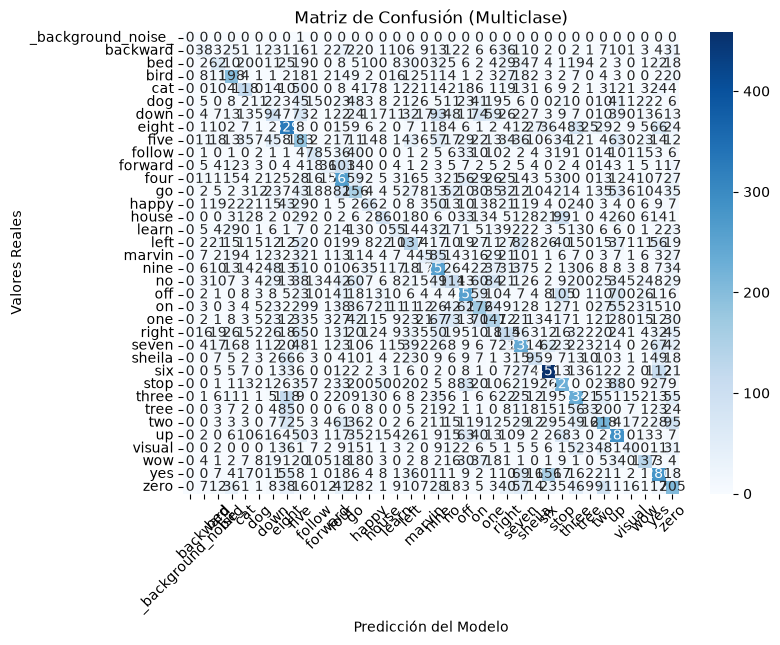

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

clases = modelo_base.classes_

# Crear un mapa de calor de la matriz de confusión
plt.figure(
    figsize=(8, 6)
) 
sns.heatmap(
    matriz_conf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases,
)

plt.xlabel("Predicción del Modelo")
plt.ylabel("Valores Reales")
plt.title("Matriz de Confusión (Multiclase)")
plt.xticks(rotation=45) 
plt.yticks(rotation=0)
plt.show()